#### Covariance and Pearson Correlation Coefficient
### Quick Overview
- **Covariance** tracks the direction of joint linear movement between two variables (whether they increase together or move in opposite directions).
- **Pearson Correlation ($r$)** rescales covariance to a standardized range between $-1$ and $+1$, quantifying both direction and strength independent of measurement units.
- **Linearity Assumption:** Both metrics strictly evaluate linear relationships and can fail to capture strong non-linear patterns (such as curves or quadratic dependencies).

#### Setup

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math

# Apply clean visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 100

## 1. Sample Covariance (`np.cov`)

* **What it does:** Measures how much two variables change together. A positive value means they move in the same direction; a negative value means they move in opposite directions.
* **Mathematical Notation:**
  $$s_{xy} = \operatorname{Cov}(X, Y) = \frac{1}{n - 1} \sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})$$
  *Where:*
  * $s_{xy}$ (*s sub x y*): Unbiased sample covariance
  * $\bar{x}$ (*x-bar*): Mean of variable $X$
  * $\bar{y}$ (*y-bar*): Mean of variable $Y$
  * $n$ (*n*): Number of observations ($n - 1$ adjusts for sample degrees of freedom)
* **Naive Example:** Study hours $X = [2, 4, 6]$ and Exam Scores $Y = [50, 70, 90]$ ($n = 3$).
  * $\bar{x} = 4$, $\bar{y} = 70$
  * Deviations $X$: $[-2, 0, 2]$, Deviations $Y$: $[-20, 0, 20]$
  * Sum of products: $(-2 \times -20) + (0 \times 0) + (2 \times 20) = 40 + 0 + 40 = 80$
  * Covariance: $\frac{80}{3 - 1} = 40.0$
* **When to use:** When calculating joint variability, portfolio risk matrices, or preparing features for Principal Component Analysis (PCA).

### Sample Covariance: Step-by-Step Numerical Example

Covariance aggregates the multiplied deviations of two variables from their respective means to see if positive deviations in $X$ pair with positive deviations in $Y$.

---

### Step-by-Step Example

#### 1. Input Datasets
$$\text{Study Hours } (X): [2, 4, 6] \quad (n = 3)$$
$$\text{Exam Scores } (Y): [50, 70, 90] \quad (n = 3)$$

#### 2. Calculate Means
$$\bar{x} = \frac{2 + 4 + 6}{3} = 4$$
$$\bar{y} = \frac{50 + 70 + 90}{3} = 70$$

#### 3. Compute Deviations and Product of Deviations
| Student | $x_i$ | $y_i$ | $(x_i - \bar{x})$ | $(y_i - \bar{y})$ | Product $(x_i - \bar{x})(y_i - \bar{y})$ |
|---|---|---|---|---|---|
| 1 | 2 | 50 | $2 - 4 = -2$ | $50 - 70 = -20$ | $(-2) \times (-20) = 40$ |
| 2 | 4 | 70 | $4 - 4 = 0$ | $70 - 70 = 0$ | $0 \times 0 = 0$ |
| 3 | 6 | 90 | $6 - 4 = 2$ | $90 - 70 = 20$ | $2 \times 20 = 40$ |

#### 4. Sum of Products
$$\sum (x_i - \bar{x})(y_i - \bar{y}) = 40 + 0 + 40 = 80$$

#### 5. Calculate Sample Covariance
$$\operatorname{Cov}(X,Y) = \frac{80}{3 - 1} = \frac{80}{2} = 40.0$$

Plain Python Covariance: 40.0
var([2 4 6]) study hours var(x): 4.0
var([50 70 90]) exam scores var(y): 400.0
NumPy Covariance Cov(X, Y): 40.0

NumPy np.cov Matrix:
[[  4.  40.]
 [ 40. 400.]]


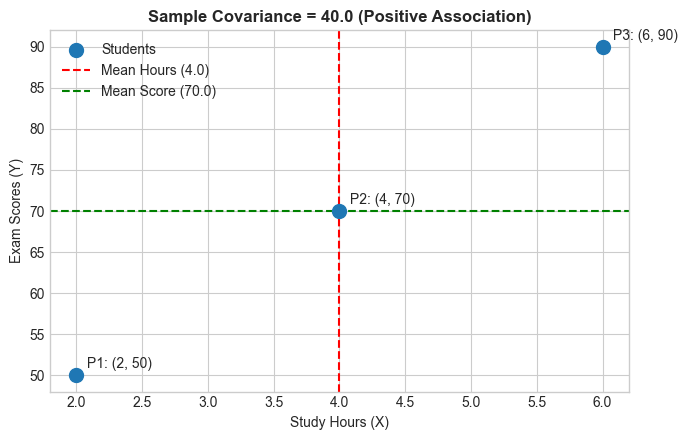

In [5]:
# --- 1. DATA PREPARATION ---
study_hours = np.array([2, 4, 6])
exam_scores = np.array([50, 70, 90])
n = len(study_hours)

# --- 2. PLAIN PYTHON IMPLEMENTATION ---
mean_x = sum(study_hours) / n
mean_y = sum(exam_scores) / n
dev_x = [x - mean_x for x in study_hours]
dev_y = [y - mean_y for y in exam_scores]
prod_dev = [dx * dy for dx, dy in zip(dev_x, dev_y)]
cov_python = sum(prod_dev) / (n - 1)

# --- 3. NUMPY IMPLEMENTATION ---
# rowvar=False treats columns/1D-arrays as variables
cov_matrix_numpy = np.cov(study_hours, exam_scores, rowvar=False, ddof=1) # ddof(delta degrees of freedom)  =1 for sample covariance

cov_numpy = cov_matrix_numpy[0, 1]
'''
np.cov returns the covariance matrix, 
where the diagonal elements are the variances of each variable and 
the off-diagonal elements are the covariances between variables.
cov_matrix: 
[[var(x) cov(x, y)]
 [cov(y, x) var(y)]]
'''

print(f"Plain Python Covariance: {cov_python:.1f}")
print(f"var({study_hours}) study hours var(x): {np.var(study_hours, ddof=1):.1f}")
print(f"var({exam_scores}) exam scores var(y): {np.var(exam_scores, ddof=1):.1f}")
print(f"NumPy Covariance Cov(X, Y): {cov_numpy:.1f}\n")
print(f"NumPy np.cov Matrix:\n{cov_matrix_numpy}")

# --- 4. VISUAL REPRESENTATION ---
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(study_hours, exam_scores, color='#1f77b4', s=100, zorder=5, label='Students')
ax.axvline(mean_x, color='red', linestyle='--', label=f'Mean Hours ({mean_x:.1f})')
ax.axhline(mean_y, color='green', linestyle='--', label=f'Mean Score ({mean_y:.1f})')

for i in range(n):
    ax.annotate(f' P{i+1}: ({study_hours[i]}, {exam_scores[i]})',
                (study_hours[i], exam_scores[i]), textcoords="offset points", xytext=(5,5))

ax.set_xlabel('Study Hours (X)')
ax.set_ylabel('Exam Scores (Y)')
ax.set_title(f'Sample Covariance = {cov_numpy:.1f} (Positive Association)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

## 2. Pearson Correlation Coefficient (`np.corrcoef`)

* **What it does:** Standardizes covariance by scaling it between $-1$ and $+1$ using the standard deviations of both variables. It isolates the strength and direction of linear relationship.
* **Mathematical Notation:**
  $$r_{xy} = \frac{\operatorname{Cov}(X, Y)}{s_x \cdot s_y} = \frac{\sum_{i=1}^{n} (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n} (x_i - \bar{x})^2} \sqrt{\sum_{i=1}^{n} (y_i - \bar{y})^2}}$$
  *Where:*
  * $r_{xy}$ (*r sub x y*): Sample Pearson correlation coefficient
  * $s_x$ (*s sub x*): Sample standard deviation of $X$
  * $s_y$ (*s sub y*): Sample standard deviation of $Y$
* **Naive Example:** Using our previous study data ($X=[2, 4, 6]$, $Y=[50, 70, 90]$):
  * $\operatorname{Cov}(X,Y) = 40.0$
  * $s_x = \sqrt{\frac{8}{2}} = 2.0$
  * $s_y = \sqrt{\frac{800}{2}} = 20.0$
  * Pearson Correlation: $r = \frac{40.0}{2.0 \times 20.0} = \frac{40.0}{40.0} = 1.0$ (Perfect Positive Linear Correlation)
* **When to use:** When assessing direct linear relationships, checking feature collinearity, or finding feature-target correlation scale-independently.

Plain Python Pearson r: 1.0000
NumPy np.corrcoef r:   1.0000
Pandas Series corr r:  1.0000

____________________________________________________________
   Hours  Scores
0      2      50
1      4      70
2      6      90
____________________________________________________________
        count  mean   std   min   25%   50%   75%   max
Hours     3.0   4.0   2.0   2.0   3.0   4.0   5.0   6.0
Scores    3.0  70.0  20.0  50.0  60.0  70.0  80.0  90.0


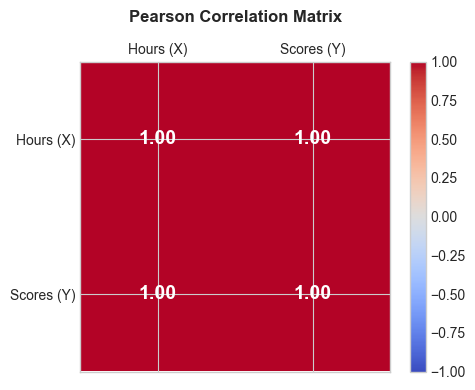

In [7]:
# --- 1. PLAIN PYTHON IMPLEMENTATION ---
var_x = sum((x - mean_x) ** 2 for x in study_hours) / (n - 1)
var_y = sum((y - mean_y) ** 2 for y in exam_scores) / (n - 1)
std_x = math.sqrt(var_x)
std_y = math.sqrt(var_y)

r_python = cov_python / (std_x * std_y)

# --- 2. NUMPY & PANDAS IMPLEMENTATIONS ---
r_numpy_matrix = np.corrcoef(study_hours, exam_scores)
r_numpy = r_numpy_matrix[0, 1]
'''
np.corrcoef returns the Pearson correlation coefficient matrix,
where the diagonal elements are always 1 (correlation of a variable with itself) and
the off-diagonal elements are the Pearson correlation coefficients between variables.
r_numpy_matrix:
[[1        r(x, y)]
 [r(y, x) 1       ]]
'''
df = pd.DataFrame({'Hours': study_hours, 'Scores': exam_scores})
r_pandas = df['Hours'].corr(df['Scores'])

print(f"Plain Python Pearson r: {r_python:.4f}")
print(f"NumPy np.corrcoef r:   {r_numpy:.4f}")
print(f"Pandas Series corr r:  {r_pandas:.4f}\n")
print("_" * 60)
print(df)
print("_" * 60)
print(df.describe().T)


# --- 3. VISUAL HEATMAP REPRESENTATION ---
fig, ax = plt.subplots(figsize=(5, 4))
cax = ax.matshow(r_numpy_matrix, cmap='coolwarm', vmin=-1, vmax=1)
fig.colorbar(cax)

for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{r_numpy_matrix[i, j]:.2f}", ha='center', va='center',
                color='white' if abs(r_numpy_matrix[i, j]) > 0.5 else 'black', fontweight='bold', fontsize=14)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Hours (X)', 'Scores (Y)'])
ax.set_yticklabels(['Hours (X)', 'Scores (Y)'])
ax.set_title('Pearson Correlation Matrix', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 3. Straightforward Guide: Where Does Each Metric Fail?

In bivariate analytics, each metric is designed for a specific statistical assumption. When those assumptions are violated, the metric **FAILS** and provides misleading conclusions. Below is the straightforward breakdown of exactly where and why each metric fails:

---

#### ❌ Failure Case 1: Where Covariance Fails — The Scale / Unit Trap
* **The Flaw:** Covariance is not standardized; its value depends completely on the units of measurement ($Units_X \times Units_Y$).
* **Concrete Example:**
  * Measure Height in **Meters** vs Weight in kg $\implies \operatorname{Cov}(X, Y) = \mathbf{1.03}$
  * Measure the **exact same people** in **Millimeters** vs Weight in kg $\implies \operatorname{Cov}(X, Y) = \mathbf{1031.27}$ (A 1,000x jump!)
* **Why it Fails:** The physical relationship and correlation did not change at all ($r = 0.988$ in both cases), but covariance jumped by 1,000x. You cannot judge relationship strength by looking at covariance alone.

---

#### ❌ Failure Case 2: Where Pearson Fails — The Symmetrical Parabola Trap ($Y = X^2$)
* **The Flaw:** Pearson's $r$ strictly looks for a **straight line** ($Y = \beta_0 + \beta_1 X$).
* **Concrete Example:** $Y = X^2$ over $X \in [-10, +10]$.
  * $Y$ is **100% deterministically predictable** from $X$ (zero randomness).
  * However, the negative linear slope on the left ($X < 0$) perfectly cancels the positive linear slope on the right ($X > 0$).
  * **Result:** Pearson's $r = \mathbf{0.00}$ (Flat horizontal line)!
* **Why it Fails:** Zero correlation ($r = 0$) does **NOT** mean independence; it only means zero *linear* association.

---

#### ⚠️ Failure Case 3: Where Pearson is Penalized, but Spearman WINS — Monotonic Curves ($Y = e^X$)
* **The Flaw:** A curved line cannot be accurately modeled by a single straight slope.
* **Concrete Example:** Exponential growth $Y = \exp(X)$ over $X \in [1, 5]$.
  * The relationship is strictly increasing ($100\%$ monotonic: whenever $X$ increases, $Y$ always increases).
  * **Pearson's $r = \mathbf{0.896}$:** Penalized because straight-line residuals grow larger as the curve bends.
  * **Spearman's $\rho = \mathbf{1.000}$ (WINNER!):** Because ranking strips away the exponential curvature, $\text{Rank}(e^X) = \text{Rank}(X)$, giving a perfect score.

---

#### ❌ Failure Case 4: Where Pearson Collapses, but Spearman Holds — The Single Outlier Trap
* **The Flaw:** Pearson calculates squared distance deviations, giving extreme outliers massive leverage.
* **Concrete Example:** A clean dataset of $n = 40$ points with $r = 0.993$ is corrupted by **just one single rogue point** at $(48, -35)$:
  * **Pearson's $r$ collapses:** Drops from $0.993 \to \mathbf{0.694}$ (Loss of $-0.299$ from 1 single point!).
  * **Spearman's $\rho$ holds strong:** Drops only from $0.993 \to \mathbf{0.864}$ (WINNER!).
* **Why Spearman Wins:** Ranks bound any outlier to maximum rank $n$; it cannot exert infinite leverage.

---

#### ❌ Failure Case 5: Where BOTH Pearson & Spearman Fail — Closed Circular Patterns ($X^2 + Y^2 = R^2$)
* **The Flaw:** Both Pearson and Spearman require directional monotonicity (consistently going up or down).
* **Concrete Example:** Points arranged along a circle $X^2 + Y^2 = R^2$:
  * There is a rigid mathematical relationship, but the ranks go up and down in loops.
  * **Pearson $r = \mathbf{0.011 \approx 0}$ (FAILS)**
  * **Spearman $\rho = \mathbf{0.010 \approx 0}$ (FAILS)**
* **Solution:** Non-monotonic patterns require **Distance Correlation** or **Mutual Information ($MI$)**.

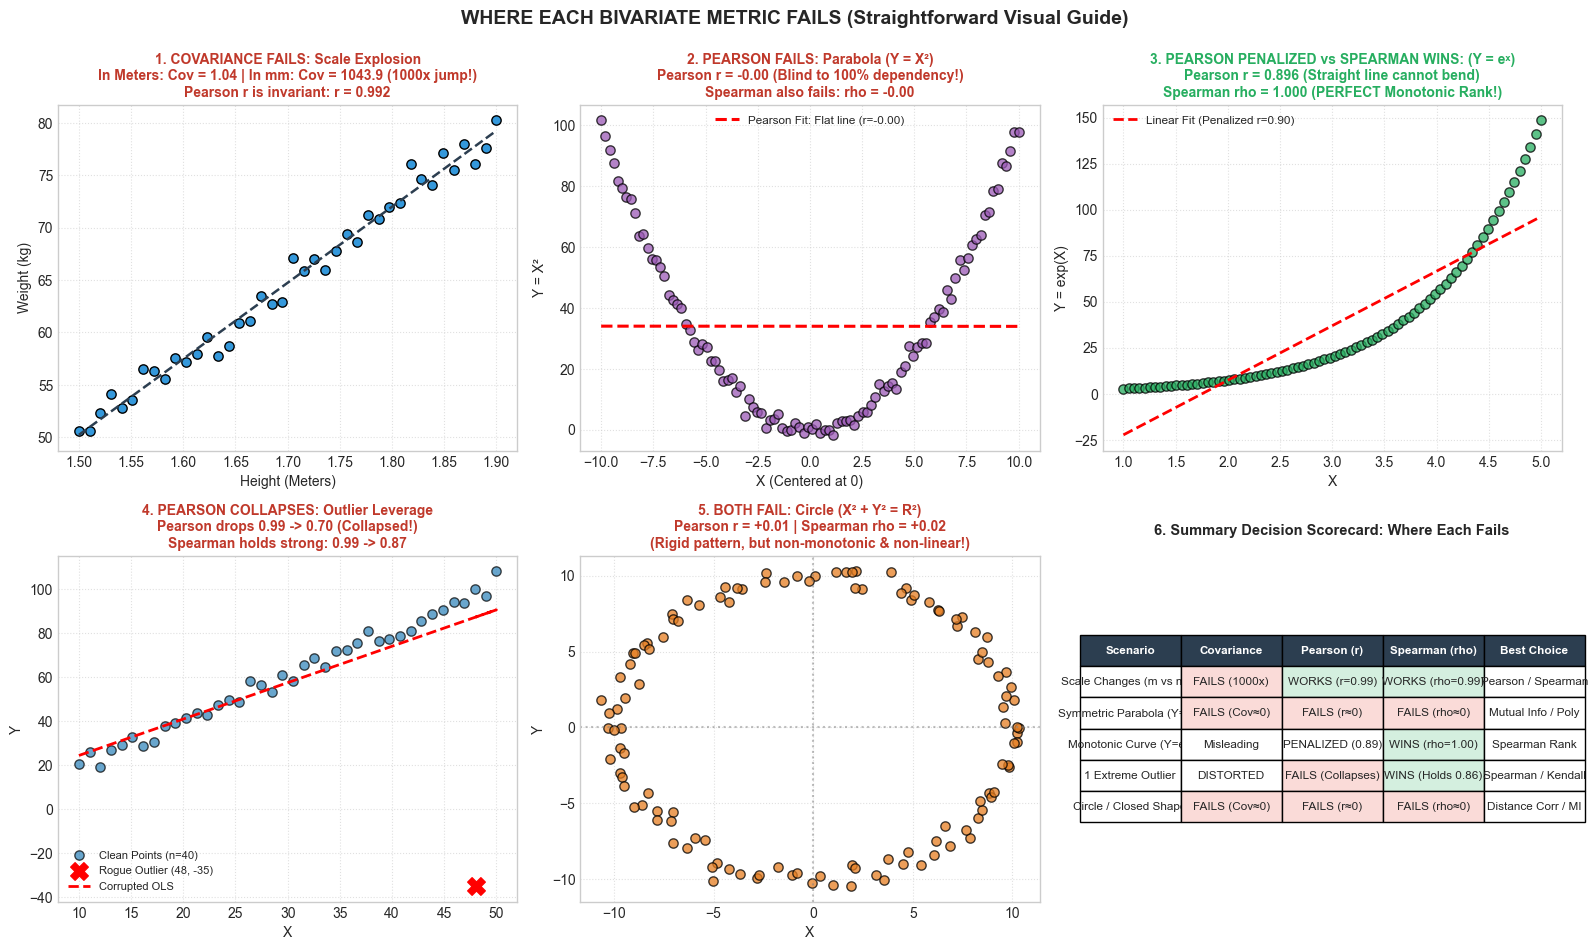

In [9]:
# ==============================================================================
# VISUAL BENCHMARK: WHERE EACH BIVARIATE METRIC FAILS (STRAIGHTFORWARD GUIDE)
# ==============================================================================
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(42)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
axes = axes.flatten()

# ------------------------------------------------------------------------------
# 1. WHERE COVARIANCE FAILS: Scale / Unit Explosion
# ------------------------------------------------------------------------------
height_m = np.linspace(1.5, 1.9, 40)
weight_kg = 50 + 75 * (height_m - 1.5) + np.random.normal(0, 1.2, 40)
cov_m = np.cov(height_m, weight_kg, ddof=1)[0, 1]
cov_mm = np.cov(height_m * 1000.0, weight_kg, ddof=1)[0, 1]
r_m, _ = stats.pearsonr(height_m, weight_kg)

ax0 = axes[0]
ax0.scatter(height_m, weight_kg, color='#3498db', edgecolors='k', s=45)
m0, b0 = np.polyfit(height_m, weight_kg, 1)
ax0.plot(height_m, b0 + m0 * height_m, color='#2c3e50', linestyle='--', linewidth=1.8)
ax0.set_title(f'1. COVARIANCE FAILS: Scale Explosion\nIn Meters: Cov = {cov_m:.2f} | In mm: Cov = {cov_mm:.1f} (1000x jump!)\nPearson r is invariant: r = {r_m:.3f}', 
              fontweight='bold', fontsize=10, color='#c0392b')
ax0.set_xlabel('Height (Meters)')
ax0.set_ylabel('Weight (kg)')
ax0.grid(True, linestyle=':', alpha=0.6)

# ------------------------------------------------------------------------------
# 2. WHERE PEARSON FAILS: Symmetric Parabola (Y = X^2)
# ------------------------------------------------------------------------------
x_quad = np.linspace(-10, 10, 100)
y_quad = x_quad**2 + np.random.normal(0, 2, 100)
r_q, _ = stats.pearsonr(x_quad, y_quad)
rho_q, _ = stats.spearmanr(x_quad, y_quad)

ax1 = axes[1]
ax1.scatter(x_quad, y_quad, color='#9b59b6', edgecolors='k', alpha=0.75, s=45)
m1, b1 = np.polyfit(x_quad, y_quad, 1)
ax1.plot(x_quad, b1 + m1 * x_quad, color='red', linestyle='--', linewidth=2.2, label=f'Pearson Fit: Flat line (r={r_q:+.2f})')
ax1.set_title(f'2. PEARSON FAILS: Parabola (Y = X²)\nPearson r = {r_q:+.2f} (Blind to 100% dependency!)\nSpearman also fails: rho = {rho_q:+.2f}', 
              fontweight='bold', fontsize=10, color='#c0392b')
ax1.set_xlabel('X (Centered at 0)')
ax1.set_ylabel('Y = X²')
ax1.legend(loc='upper center', fontsize=8.5)
ax1.grid(True, linestyle=':', alpha=0.6)

# ------------------------------------------------------------------------------
# 3. PEARSON PENALIZED, SPEARMAN WINS: Exponential Curve (Y = e^X)
# ------------------------------------------------------------------------------
x_exp = np.linspace(1, 5, 80)
y_exp = np.exp(x_exp)
r_e, _ = stats.pearsonr(x_exp, y_exp)
rho_e, _ = stats.spearmanr(x_exp, y_exp)

ax2 = axes[2]
ax2.scatter(x_exp, y_exp, color='#27ae60', edgecolors='k', alpha=0.75, s=45)
m2, b2 = np.polyfit(x_exp, y_exp, 1)
ax2.plot(x_exp, b2 + m2 * x_exp, color='red', linestyle='--', linewidth=2, label=f'Linear Fit (Penalized r={r_e:.2f})')
ax2.set_title(f'3. PEARSON PENALIZED vs SPEARMAN WINS: (Y = eˣ)\nPearson r = {r_e:.3f} (Straight line cannot bend)\nSpearman rho = {rho_e:.3f} (PERFECT Monotonic Rank!)', 
              fontweight='bold', fontsize=10, color='#27ae60')
ax2.set_xlabel('X')
ax2.set_ylabel('Y = exp(X)')
ax2.legend(loc='upper left', fontsize=8.5)
ax2.grid(True, linestyle=':', alpha=0.6)

# ------------------------------------------------------------------------------
# 4. PEARSON COLLAPSES, SPEARMAN WINS: Single Extreme Outlier
# ------------------------------------------------------------------------------
x_clean = np.linspace(10, 50, 40)
y_clean = 2.0 * x_clean + np.random.normal(0, 3, 40)
x_out = np.append(x_clean, [48.0])
y_out = np.append(y_clean, [-35.0])
r_cl, _ = stats.pearsonr(x_clean, y_clean)
r_ot, _ = stats.pearsonr(x_out, y_out)
rho_cl, _ = stats.spearmanr(x_clean, y_clean)
rho_ot, _ = stats.spearmanr(x_out, y_out)

ax3 = axes[3]
ax3.scatter(x_clean, y_clean, color='#2980b9', alpha=0.7, edgecolors='k', s=45, label='Clean Points (n=40)')
ax3.scatter([48.0], [-35.0], color='red', s=160, marker='X', zorder=6, label='Rogue Outlier (48, -35)')
m3, b3 = np.polyfit(x_out, y_out, 1)
ax3.plot(x_out, b3 + m3 * x_out, color='red', linestyle='--', linewidth=2, label='Corrupted OLS')
ax3.set_title(f'4. PEARSON COLLAPSES: Outlier Leverage\nPearson drops {r_cl:.2f} -> {r_ot:.2f} (Collapsed!)\nSpearman holds strong: {rho_cl:.2f} -> {rho_ot:.2f}', 
              fontweight='bold', fontsize=10, color='#c0392b')
ax3.set_xlabel('X')
ax3.set_ylabel('Y')
ax3.legend(loc='lower left', fontsize=8)
ax3.grid(True, linestyle=':', alpha=0.6)

# ------------------------------------------------------------------------------
# 5. BOTH PEARSON & SPEARMAN FAIL: Circle / Donut Pattern
# ------------------------------------------------------------------------------
theta = np.linspace(0, 2 * np.pi, 120)
x_circ = 10 * np.cos(theta) + np.random.normal(0, 0.4, 120)
y_circ = 10 * np.sin(theta) + np.random.normal(0, 0.4, 120)
r_c, _ = stats.pearsonr(x_circ, y_circ)
rho_c, _ = stats.spearmanr(x_circ, y_circ)

ax4 = axes[4]
ax4.scatter(x_circ, y_circ, color='#e67e22', edgecolors='k', alpha=0.75, s=45)
ax4.axvline(0, color='gray', linestyle=':', alpha=0.5)
ax4.axhline(0, color='gray', linestyle=':', alpha=0.5)
ax4.set_title(f'5. BOTH FAIL: Circle (X² + Y² = R²)\nPearson r = {r_c:+.2f} | Spearman rho = {rho_c:+.2f}\n(Rigid pattern, but non-monotonic & non-linear!)', 
              fontweight='bold', fontsize=10, color='#c0392b')
ax4.set_xlabel('X')
ax4.set_ylabel('Y')
ax4.grid(True, linestyle=':', alpha=0.6)

# ------------------------------------------------------------------------------
# 6. SUMMARY SCORECARD: WHERE TO USE WHAT
# ------------------------------------------------------------------------------
ax5 = axes[5]
ax5.axis('off')
table_data = [
    ["Scenario", "Covariance", "Pearson (r)", "Spearman (rho)", "Best Choice"],
    ["Scale Changes (m vs mm)", "FAILS (1000x)", "WORKS (r=0.99)", "WORKS (rho=0.99)", "Pearson / Spearman"],
    ["Symmetric Parabola (Y=X²)", "FAILS (Cov≈0)", "FAILS (r≈0)", "FAILS (rho≈0)", "Mutual Info / Poly"],
    ["Monotonic Curve (Y=eˣ)", "Misleading", "PENALIZED (0.89)", "WINS (rho=1.00)", "Spearman Rank"],
    ["1 Extreme Outlier", "DISTORTED", "FAILS (Collapses)", "WINS (Holds 0.86)", "Spearman / Kendall"],
    ["Circle / Closed Shape", "FAILS (Cov≈0)", "FAILS (r≈0)", "FAILS (rho≈0)", "Distance Corr / MI"]
]
table = ax5.table(cellText=table_data, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(8.5)
table.scale(1.1, 1.8)
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', fontweight='bold')
    elif "FAILS" in cell.get_text().get_text():
        cell.set_facecolor('#fadbd8')
    elif "WINS" in cell.get_text().get_text() or "WORKS" in cell.get_text().get_text():
        cell.set_facecolor('#d4efdf')
ax5.set_title('6. Summary Decision Scorecard: Where Each Fails', fontweight='bold', fontsize=10.5, pad=15)

plt.suptitle('WHERE EACH BIVARIATE METRIC FAILS (Straightforward Visual Guide)', fontsize=14, fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()
